# MODEL_CLUSTER — Groupes d'utilisateurs (goûts)

Méthode (slide *Utiliser les groupes pour recommander*) :

1. **Profils** — goûts train = moyennes de notes **par genre** (+ âge / sexe normalisés).
2. **Clustering** — KMeans sur ces profils utilisateurs ; nombre de groupes fixé et documenté.
3. **Recommandation** — classer les films appréciés **dans le groupe**, exclure ceux déjà vus / seeds.
4. **Repli** — si le groupe n'a pas assez de signal → films populaires du train (volume, min. support).

Mode produit : **âge + sexe + 1–3 films** → on construit un profil requête (genres des seeds + démo), on assigne au centroïde le plus proche.

Comparaison : baseline overlap+mean et User–CF simple (même protocole).


## 1. Chargement et split


In [38]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
LIKED_THRESHOLD = 4
MAX_SEEDS = 3
TRAIN_FRAC = 0.65
MIN_SUPPORT = 22

# Clustering users — documenté
N_CLUSTERS = 8
MIN_GROUP_CANDIDATES = 5   # sinon repli popularité
CF_N_USER = 200            # UserCF témoin

np.random.seed(RANDOM_STATE)

GENRES = [
    "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime",
    "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical",
    "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western",
]

DATA_DIR = next(
    (p for p in [Path("dataset"), Path("../dataset")] if (p / "u.data.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("dataset/ introuvable")

notes = pd.read_csv(DATA_DIR / "u.data.csv")
films = pd.read_csv(DATA_DIR / "u.item.csv")
users = pd.read_csv(DATA_DIR / "u.user.csv", dtype={"zip_code": "string"}).drop(
    columns=["occupation"], errors="ignore"
)

df = notes.merge(users, on="user_id", how="left").merge(
    films, left_on="item_id", right_on="movie_id", how="left"
)
df = df.loc[df["unknown"] != 1].drop(columns=["unknown"]).copy()
df["genres"] = df[GENRES].apply(lambda row: [g for g in GENRES if row[g] == 1], axis=1)

print(f"Notes : {len(df):,} | users : {df['user_id'].nunique()} | films : {df['item_id'].nunique()}")
display(df[["user_id", "item_id", "rating", "age", "gender", "title", "genres"]].head(3))


Notes : 99,990 | users : 943 | films : 1680


,user_id,item_id,rating,age,gender,title,genres
0,196,242,3,49,M,Kolya (1996),[Comedy]
1,186,302,3,39,F,L.A. Confidential (1997),"[Crime, Film-Noir, Mystery, Thriller]"
2,22,377,1,25,M,Heavyweights (1994),"[Children's, Comedy]"


In [39]:
train = df.sample(frac=TRAIN_FRAC, random_state=RANDOM_STATE)
test = df.drop(train.index)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
print(f"Train {len(train):,} | Test {len(test):,} | TRAIN_FRAC={TRAIN_FRAC}")

movies = df.drop_duplicates("item_id").set_index("item_id")
movie_genres = movies["genres"].to_dict()
movie_title = movies["title"].to_dict()
film_genre_X = movies[GENRES].astype(float)
all_movie_ids = film_genre_X.index.to_numpy()
print(f"Films catalogue : {len(all_movie_ids)}")


Train 64,994 | Test 34,996 | TRAIN_FRAC=0.65
Films catalogue : 1680


## 2. Stats train + cas d'évaluation produit


In [40]:
film_stats = (
    train.groupby("item_id")["rating"]
    .agg(n_ratings="count", mean_rating="mean")
    .reset_index()
)
eligible = film_stats.loc[film_stats["n_ratings"] >= MIN_SUPPORT].set_index("item_id")
mean_rating = eligible["mean_rating"]
pop_count = eligible["n_ratings"]
print(f"Films éligibles (>= {MIN_SUPPORT} notes) : {len(eligible)}")

liked_train = train.loc[train["rating"] >= LIKED_THRESHOLD]
liked_test = test.loc[test["rating"] >= LIKED_THRESHOLD]
train_counts = train.groupby("item_id").size()

cand_A = liked_train.copy()
cand_A["pop"] = cand_A["item_id"].map(train_counts)


def _get_top_seeds(df_u, max_n=MAX_SEEDS):
    sorted_u = df_u.sort_values(["rating", "pop"], ascending=[False, False])
    return list(sorted_u["item_id"].unique()[:max_n])


seeds_per_user = (
    cand_A.groupby("user_id", group_keys=False)
    .apply(_get_top_seeds)
    .rename("query_ids")
)
user_demo = train.drop_duplicates("user_id").set_index("user_id")[["age", "gender"]]
relevant = liked_test.groupby("user_id")["item_id"].apply(set).rename("relevant_ids")

eval_cases = pd.concat([seeds_per_user, user_demo, relevant], axis=1, join="inner").reset_index()
eval_cases["relevant_ids"] = eval_cases.apply(
    lambda r: r["relevant_ids"] - set(r["query_ids"]), axis=1
)
eval_cases = eval_cases.loc[eval_cases["relevant_ids"].map(len) > 0].reset_index(drop=True)
print(f"Cas d'évaluation (1-{MAX_SEEDS} films) : {len(eval_cases)}")
display(eval_cases.head(3))


Films éligibles (>= 22 notes) : 769
Cas d'évaluation (1-3 films) : 940


,user_id,query_ids,age,gender,relevant_ids
0,1,"[50, 181, 258]",24,M,"{256, 1, 257, 269, 14, 270, 16, 15, 18, 19, 23..."
1,2,"[50, 127, 302]",53,F,"{1, 100, 293, 299, 13, 237, 251, 273, 306, 277..."
2,3,"[340, 321, 320]",23,M,"{327, 328, 344, 346, 347, 348, 318}"


## 3. Profils utilisateurs (moyennes par genre)

Pour chaque user train : note moyenne sur les films de chaque genre (NaN → 0 si jamais noté).
On ajoute `age` normalisé et `gender` (1 = M, 0 = F) pour ancrer le profil démo.


In [41]:
def build_user_genre_profiles(ratings: pd.DataFrame) -> pd.DataFrame:
    """Moyenne de notes par genre (users × GENRES) + âge / sexe."""
    tm = ratings[["user_id", "item_id", "rating", "age", "gender"]].merge(
        movies[GENRES], left_on="item_id", right_index=True, how="left"
    )
    cols = {}
    for g in GENRES:
        cols[g] = tm.loc[tm[g] == 1].groupby("user_id")["rating"].mean()
    prof = pd.DataFrame(cols)
    demo = ratings.drop_duplicates("user_id").set_index("user_id")[["age", "gender"]]
    prof["age"] = demo["age"]
    prof["gender_m"] = (demo["gender"] == "M").astype(float)
    return prof


user_profiles = build_user_genre_profiles(train)
feat_cols = GENRES + ["age", "gender_m"]
X_raw = user_profiles[feat_cols].fillna(0.0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw.values)

print(f"Profils users train : {len(user_profiles)} × {len(feat_cols)} features")
display(user_profiles[GENRES].head(3).round(2))


Profils users train : 943 × 20 features


,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
user_id,,,,,,,,,,,,,,,,,,
1,3.12,2.92,3.33,2.25,3.38,3.47,4.8,3.92,NaN,5.0,3.44,3.11,2.67,3.68,3.92,3.53,3.50,3.33
2,3.62,4.33,NaN,2.67,4.00,4.00,NaN,3.82,3.0,5.0,3.00,NaN,3.50,4.09,3.75,3.67,3.67,NaN
3,2.62,3.50,NaN,NaN,2.33,3.00,5.0,2.45,NaN,2.0,2.25,2.00,3.14,3.00,2.75,2.60,2.50,NaN


## 4. Clustering KMeans des utilisateurs

**Choix :** `N_CLUSTERS` groupes (fixé, défaut 8). On documente la taille de chaque cluster.


In [42]:
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
user_cluster = dict(zip(X_raw.index.astype(int), cluster_labels.astype(int)))

sizes = pd.Series(cluster_labels).value_counts().sort_index()
print(f"KMeans : {N_CLUSTERS} clusters sur {len(user_cluster)} users")
print(sizes.to_dict())

# Films aimés par cluster (pour le ranking intra-groupe)
liked_train = liked_train.copy()
liked_train["cluster"] = liked_train["user_id"].map(user_cluster)

cluster_film_scores = {}
for cid, grp in liked_train.dropna(subset=["cluster"]).groupby("cluster"):
    # score = somme des notes aimées dans le groupe (qualité × volume local)
    s = grp.groupby("item_id")["rating"].sum()
    cluster_film_scores[int(cid)] = s.to_dict()

print(
    "Films distincts aimés / cluster :",
    {c: len(v) for c, v in cluster_film_scores.items()},
)

# Structures UserCF témoin
liked_by_user = (
    liked_train.groupby("user_id")[["item_id", "rating"]]
    .apply(lambda x: list(zip(x["item_id"], x["rating"])))
    .to_dict()
)
fans_of = {
    mid: list(
        zip(
            grp["user_id"].to_numpy(),
            grp["rating"].to_numpy(),
            grp["age"].to_numpy(),
            grp["gender"].to_numpy(),
        )
    )
    for mid, grp in liked_train.groupby("item_id")
}


KMeans : 8 clusters sur 943 users
{0: 161, 1: 101, 2: 177, 3: 158, 4: 65, 5: 157, 6: 50, 7: 74}
Films distincts aimés / cluster : {0: 1085, 1: 512, 2: 1150, 3: 924, 4: 256, 5: 648, 6: 333, 7: 411}


## 5. Recommenders — baseline, cluster-groupes, UserCF, repli


In [43]:
def _seen(query_ids, liked_train_ids=None):
    if isinstance(query_ids, (int, np.integer)):
        seeds = {int(query_ids)}
    else:
        seeds = set(int(x) for x in query_ids)
    s = set(liked_train_ids) if liked_train_ids is not None else set()
    return s.union(seeds), seeds


def recommend_popular(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    """Repli : films train les plus notés (volume), hors vus."""
    seen, _ = _seen(query_ids, liked_train_ids)
    cands = [(mid, int(n)) for mid, n in pop_count.items() if mid not in seen]
    cands.sort(key=lambda x: (-x[1], x[0]))
    return [m for m, _ in cands[:k]]


def recommend_baseline(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    union_g = set()
    for qid in seeds:
        union_g.update(movie_genres.get(qid, []))
    if not union_g:
        return recommend_popular(query_ids, k=k, liked_train_ids=liked_train_ids)
    scores = [
        (mid, float(m))
        for mid, m in mean_rating.items()
        if mid not in seen and union_g & set(movie_genres.get(mid, []))
    ]
    scores.sort(key=lambda x: (-x[1], x[0]))
    return [m for m, _ in scores[:k]]


def _query_profile_vector(seeds, age, gender):
    """Profil cold-start : pour chaque genre des seeds, note proxy (= aimé).

    Aligne l'échelle sur les profils train (moyenne de notes par genre).
    """
    genre_means = np.zeros(len(GENRES), dtype=float)
    seed_list = [s for s in seeds if s in film_genre_X.index]
    if seed_list:
        # films aimés en entrée → on leur attribue LIKED_THRESHOLD comme note proxy
        proxy = float(LIKED_THRESHOLD)
        for j, g in enumerate(GENRES):
            present = film_genre_X.loc[seed_list, g].to_numpy()
            if present.sum() > 0:
                genre_means[j] = proxy
    age_val = 30.0 if age is None else float(age)
    gender_m = 1.0 if (gender or "M") == "M" else 0.0
    raw = np.concatenate([genre_means, [age_val, gender_m]])
    return scaler.transform(raw.reshape(1, -1))[0]


def assign_cluster(seeds, age, gender):
    vec = _query_profile_vector(seeds, age, gender)
    # centroïde le plus proche (euclidien, même espace que KMeans)
    dists = np.linalg.norm(kmeans.cluster_centers_ - vec, axis=1)
    return int(np.argmin(dists))


def recommend_user_cluster(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    """Reco intra-groupe + repli popularité si signal insuffisant."""
    seen, seeds = _seen(query_ids, liked_train_ids)

    # Si on connaît l'user train, utiliser son vrai cluster
    if user_id is not None and int(user_id) in user_cluster:
        cid = user_cluster[int(user_id)]
    else:
        cid = assign_cluster(seeds, age, gender)

    film_scores = cluster_film_scores.get(cid, {})
    ranked = [
        (mid, sc)
        for mid, sc in film_scores.items()
        if mid not in seen and mid in eligible.index
    ]
    ranked.sort(key=lambda x: (-x[1], x[0]))
    out = [m for m, _ in ranked[:k]]

    if len(out) < MIN_GROUP_CANDIDATES:
        # Repli : compléter avec popularité train
        pop = recommend_popular(query_ids, k=k, liked_train_ids=liked_train_ids)
        for mid in pop:
            if mid not in out and mid not in seen:
                out.append(mid)
            if len(out) >= k:
                break
    return out[:k]


def recommend_user_cf(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    age_val = 30.0 if age is None else float(age)
    gender_val = "M" if gender is None else gender
    neighbors = []
    for qid in seeds:
        for uid, rat, a, g in fans_of.get(qid, []):
            sex = 1.0 if g == gender_val else 0.0
            age_term = 1.0 - min(abs(age_val - float(a)) / 95.0, 1.0)
            neighbors.append((int(uid), (0.2 * sex + 0.8 * age_term) * float(rat) / 5.0))
    neighbors.sort(key=lambda x: -x[1])
    neighbors = neighbors[:CF_N_USER]
    scores = {}
    for vid, sim in neighbors:
        for mid, rat in liked_by_user.get(vid, []):
            if mid in seen:
                continue
            scores[mid] = scores.get(mid, 0.0) + float(sim) * float(rat)
    return [m for m, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:k]]


ex = eval_cases.iloc[0]
qids = ex["query_ids"]
kw = dict(age=ex["age"], gender=ex["gender"], liked_train_ids=None, user_id=None)
cid = assign_cluster(set(qids), ex["age"], ex["gender"])
print("Seeds :", [movie_title.get(i) for i in qids], f"| age={ex['age']} gender={ex['gender']} → cluster {cid}")
print("Baseline :", [movie_title.get(i) for i in recommend_baseline(qids, 5, **kw)])
print("Cluster  :", [movie_title.get(i) for i in recommend_user_cluster(qids, 5, **kw)])
print("UserCF   :", [movie_title.get(i) for i in recommend_user_cf(qids, 5, **kw)])
print("Populaire:", [movie_title.get(i) for i in recommend_popular(qids, 5, **kw)])


Seeds : ['Star Wars (1977)', 'Return of the Jedi (1983)', 'Contact (1997)'] | age=24 gender=M → cluster 1
Baseline : ['Casablanca (1942)', "Schindler's List (1993)", 'Shawshank Redemption, The (1994)', 'Citizen Kane (1941)', 'Secrets & Lies (1996)']
Cluster  : ['Air Force One (1997)', 'Scream (1996)', 'Titanic (1997)', 'Toy Story (1995)', 'Liar Liar (1997)']
UserCF   : ['Raiders of the Lost Ark (1981)', 'Empire Strikes Back, The (1980)', 'Princess Bride, The (1987)', 'Silence of the Lambs, The (1991)', 'Fugitive, The (1993)']
Populaire: ['Scream (1996)', 'Fargo (1996)', 'English Patient, The (1996)', 'Independence Day (ID4) (1996)', 'Liar Liar (1997)']


## 6. Évaluation produit


In [44]:
def precision_at_k(recommended, relevant, k):
    top = recommended[:k]
    if not top:
        return 0.0
    return sum(1 for m in top if m in relevant) / k


def evaluate_product(recommend_fn, cases, ks=(5, 10), max_k=10):
    rows = []
    for _, row in cases.iterrows():
        rec = recommend_fn(
            row["query_ids"],
            k=max_k,
            age=row["age"],
            gender=row["gender"],
            liked_train_ids=None,
            user_id=None,  # cold-start produit
        )
        rows.append({f"P@{k}": precision_at_k(rec, row["relevant_ids"], k) for k in ks})
    return pd.DataFrame(rows)


methods = [
    ("baseline_overlap_mean", recommend_baseline),
    ("popular_fallback", recommend_popular),
    ("user_cluster_groups", recommend_user_cluster),
    ("user_cf_global", recommend_user_cf),
]

per_case = {}
summaries = []
for name, fn in methods:
    scores = evaluate_product(fn, eval_cases)
    per_case[name] = scores
    summaries.append(
        {
            "method": name,
            "P@5": scores["P@5"].mean(),
            "P@10": scores["P@10"].mean(),
            "écart-type": scores["P@5"].std(ddof=1),
        }
    )

results = pd.DataFrame(summaries)
print(f"Situation produit — {len(eval_cases)} cas | N_CLUSTERS={N_CLUSTERS} | seed={RANDOM_STATE}")
display(results.round(4))

base_p5 = per_case["baseline_overlap_mean"]["P@5"]
print("\nLift vs baseline (P@5, test t apparié) :")
for name in ["popular_fallback", "user_cluster_groups", "user_cf_global"]:
    s = per_case[name]["P@5"]
    lift = s.mean() - base_p5.mean()
    p = stats.ttest_rel(s, base_p5).pvalue
    print(f"  {name:22s}  lift={lift:+.4f}  p={p:.2e}")


Situation produit — 940 cas | N_CLUSTERS=8 | seed=42


,method,P@5,P@10,écart-type
0,baseline_overlap_mean,0.0806,0.0810,0.1403
1,popular_fallback,0.1555,0.1356,0.1644
2,user_cluster_groups,0.1328,0.1187,0.1596
3,user_cf_global,0.1860,0.1590,0.1857



Lift vs baseline (P@5, test t apparié) :
  popular_fallback        lift=+0.0749  p=7.57e-30
  user_cluster_groups     lift=+0.0521  p=1.28e-14
  user_cf_global          lift=+0.1053  p=3.23e-51


## 7. Sensibilité au nombre de groupes


In [45]:
def eval_n_clusters(n_clusters):
    km = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    uc = dict(zip(X_raw.index.astype(int), labels.astype(int)))
    lt = liked_train.copy()
    lt["cluster"] = lt["user_id"].map(uc)
    cfs = {}
    for cid, grp in lt.dropna(subset=["cluster"]).groupby("cluster"):
        cfs[int(cid)] = grp.groupby("item_id")["rating"].sum().to_dict()

    def rec(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
        seen, seeds = _seen(query_ids, liked_train_ids)
        vec = _query_profile_vector(seeds, age, gender)
        # re-scale query with same scaler, compare to this km centers
        dists = np.linalg.norm(km.cluster_centers_ - vec, axis=1)
        cid = int(np.argmin(dists))
        ranked = [
            (mid, sc)
            for mid, sc in cfs.get(cid, {}).items()
            if mid not in seen and mid in eligible.index
        ]
        ranked.sort(key=lambda x: (-x[1], x[0]))
        out = [m for m, _ in ranked[:k]]
        if len(out) < MIN_GROUP_CANDIDATES:
            for mid in recommend_popular(query_ids, k=k, liked_train_ids=liked_train_ids):
                if mid not in out and mid not in seen:
                    out.append(mid)
                if len(out) >= k:
                    break
        return out[:k]

    sc = evaluate_product(rec, eval_cases)
    return float(sc["P@5"].mean()), float(sc["P@10"].mean())


grid_rows = []
for n in [4, 6, 8, 10, 12, 16]:
    p5, p10 = eval_n_clusters(n)
    grid_rows.append({"N_CLUSTERS": n, "P@5": p5, "P@10": p10})
    print(f"N={n:2d} → P@5={p5:.4f}  P@10={p10:.4f}")

grid_df = pd.DataFrame(grid_rows).sort_values("P@5", ascending=False)
display(grid_df.round(4))
best_n = int(grid_df.iloc[0]["N_CLUSTERS"])
print(f"Meilleur N_CLUSTERS sur cette grille : {best_n}")


N= 4 → P@5=0.1306  P@10=0.1045
N= 6 → P@5=0.1166  P@10=0.1239
N= 8 → P@5=0.1328  P@10=0.1187
N=10 → P@5=0.1430  P@10=0.1210
N=12 → P@5=0.1200  P@10=0.1097
N=16 → P@5=0.1157  P@10=0.1085


,N_CLUSTERS,P@5,P@10
3,10,0.1430,0.1210
2,8,0.1328,0.1187
0,4,0.1306,0.1045
4,12,0.1200,0.1097
1,6,0.1166,0.1239
5,16,0.1157,0.1085


Meilleur N_CLUSTERS sur cette grille : 10


## 8. Graphique + lecture


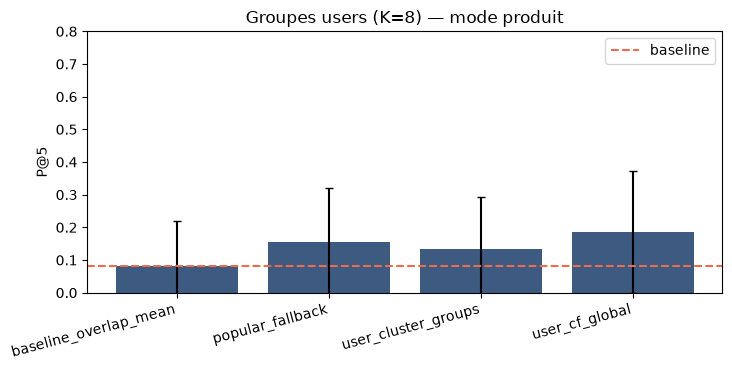

Lecture courte :
• Baseline=8.1% | Populaire=15.6% | Cluster groupes=13.3% | UserCF=18.6%.
• Les groupes de goûts battent la baseline → signal métier utile.
• UserCF reste devant : le cluster résume le voisinage, il n'égale pas un CF fin.
• N_CLUSTERS documenté = 8 (grille §7 : meilleur empirique = 10).


In [46]:
plot_df = results.set_index("method").loc[
    ["baseline_overlap_mean", "popular_fallback", "user_cluster_groups", "user_cf_global"]
]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["P@5"], yerr=plot_df["écart-type"], capsize=3, color="#3d5a80")
ax.axhline(plot_df.loc["baseline_overlap_mean", "P@5"], color="#ee6c4d", ls="--", label="baseline")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=15, ha="right")
ax.set_ylabel("P@5")
ax.set_ylim(0, 0.8)
ax.set_title(f"Groupes users (K={N_CLUSTERS}) — mode produit")
ax.legend()
plt.tight_layout()
plt.show()

clu = results.loc[results["method"] == "user_cluster_groups", "P@5"].iloc[0]
base = results.loc[results["method"] == "baseline_overlap_mean", "P@5"].iloc[0]
glob = results.loc[results["method"] == "user_cf_global", "P@5"].iloc[0]
pop = results.loc[results["method"] == "popular_fallback", "P@5"].iloc[0]

print("Lecture courte :")
print(f"• Baseline={base:.1%} | Populaire={pop:.1%} | Cluster groupes={clu:.1%} | UserCF={glob:.1%}.")
if clu > base:
    print("• Les groupes de goûts battent la baseline → signal métier utile.")
else:
    print("• Les groupes ne battent pas encore la baseline : revoir N ou le profil requête.")
if clu < glob:
    print("• UserCF reste devant : le cluster résume le voisinage, il n'égale pas un CF fin.")
print(
    f"• N_CLUSTERS documenté = {N_CLUSTERS} "
    f"(grille §7 : meilleur empirique = {best_n})."
)
